# Exploration

small playground to look at the algebra: blade names, single blade products and the cayley table.

In [154]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from pga_engine.algebra import PGA3D, Algebra, _resolve_bb_mult_bitmask, _set_bit_idxs
from pga_engine.products import gp
from pga_engine.utils import mv

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## helpers

`gp_table` is the scattered 3D version of the cayley table: `blade_i blade_j = gp_table[i, j, k] blade_k`. for plotting it gets collapsed back to the classic 2D table (sign + result blade per pair).

In [155]:
def blade_names(alg: Algebra = PGA3D) -> list[str]:
    """ readable name for each array index: '1', 'e0', ..., 'e0123' """
    return ["1" if b == 0 else "e" + "".join(map(str, _set_bit_idxs(b, alg.nr_unitvecs))) for b in alg.blades]


def collapse_gp_table(alg: Algebra = PGA3D) -> tuple[np.ndarray, np.ndarray]:
    """ collapses the 3D gp_table back to the classic 2D cayley table: (signs, result index) per pair (i, j). """
    signs = alg.gp_table.sum(axis=2)            # at most one nonzero entry per (i, j), so the sum is just that sign
    result = np.abs(alg.gp_table).argmax(axis=2)  # its position. for products that vanish this is 0, but the sign is 0 there anyway
    return signs, result


def plot_cayley(alg: Algebra = PGA3D, title: str = ""):
    """ annotated cayley table: row = left factor, column = right factor, cell = their product. colored by sign. """

    names = blade_names(alg)
    signs, result = collapse_gp_table(alg)
    n = alg.dim

    size = 0.55 * n
    fig, ax = plt.subplots(figsize=(size, size))
    # three light colors for -1, 0, +1, so the black text stays readable
    cmap = ListedColormap(["#f6c1d0", "#f4f4f4", "#c6e6b3"])
    ax.imshow(signs, cmap=cmap, vmin=-1.5, vmax=1.5)

    # write the product into every cell
    for i in range(n):
        for j in range(n):
            s = signs[i, j]
            text = "0" if s == 0 else ("-" if s < 0 else "") + names[result[i, j]]
            ax.text(j, i, text, ha="center", va="center", fontsize=8, color="0.6" if s == 0 else "black")

    # lines between the grade blocks
    for g in np.flatnonzero(np.diff(alg.grade)):
        ax.axhline(g + 0.5, color="0.3", lw=0.8)
        ax.axvline(g + 0.5, color="0.3", lw=0.8)

    ax.set_xticks(range(n), names, rotation=90)
    ax.set_yticks(range(n), names)
    ax.xaxis.tick_top()
    ax.set_xlabel("right factor b"); ax.xaxis.set_label_position("top")
    ax.set_ylabel("left factor a")
    ax.set_title(title or f"geometric product a b, metric {alg.metric}", pad=12)
    ax.tick_params(length=0)
    fig.tight_layout()
    return fig

## a single basis blade product

In [156]:
names = blade_names()
i, j = 15, 8   # e0123 * e12

sgn, res = _resolve_bb_mult_bitmask(PGA3D.blades[i], PGA3D.blades[j], PGA3D.metric)

print(f"input:  {names[i]} = {PGA3D.blades[i]:04b},  {names[j]} = {PGA3D.blades[j]:04b}")
print(f"result: {sgn=}, blade {res:04b} = {names[PGA3D.blade_index[res]]}")

input:  e0123 = 1111,  e12 = 0110
result: sgn=-1, blade 1001 = e03


## cayley table of 3D PGA

row = left factor, column = right factor, so the table is read as `row * column`. green = positive, pink = negative, grey = 0. the lines separate the grades.

all the grey zeros come from a shared e0 (e0² = 0). also visible: the table isn't symmetric, the geometric product doesn't commute.

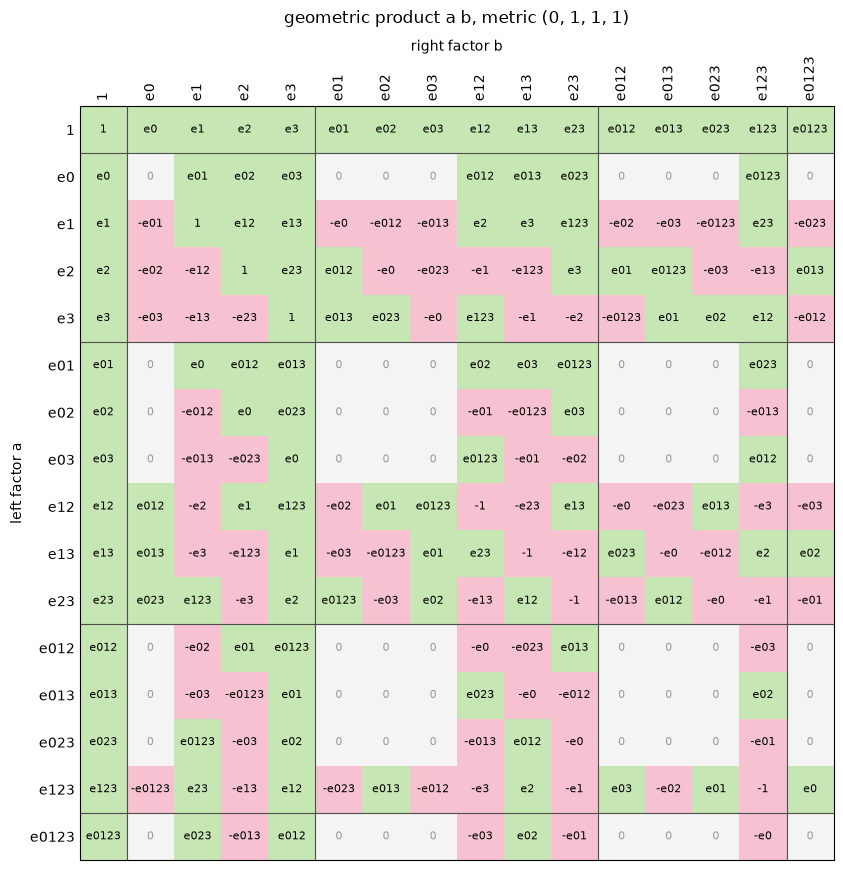

In [157]:
plot_cayley(PGA3D)
plt.show()

## other metrics

plain 3D euclidean GA (unit vectors e0, e1, e2, all squaring to +1): no zeros at all, and the bivectors e01, e02, e12 square to -1 like quaternions.

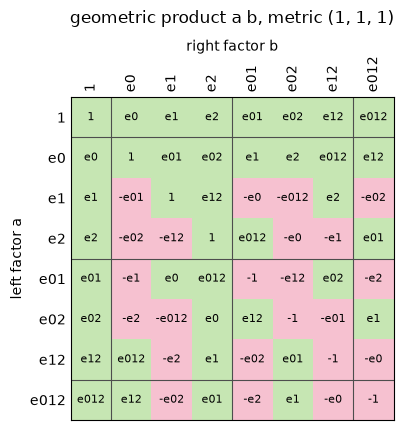

In [158]:
plot_cayley(Algebra.from_metric((1, 1, 1)))
plt.show()

## general geometric product

In [159]:
a = mv(e1=1, e2=2, e3=3)
b = mv(e1=1, e2=-1)

out = gp(a, b)
print(" + ".join(f"{c:g} {n}" for c, n in zip(out, blade_names()) if c != 0))

-1 1 + -3 e12 + -3 e13 + 3 e23
